In [17]:

# ============================================================
# IMPORTAÇÕES + CARREGAMENTO DO DATASET
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import urllib.request
import warnings
warnings.filterwarnings('ignore')

# Configurações visuais
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

# ------------------------------------------------------------
# Carregamento inteligente do dataset
# ------------------------------------------------------------
arquivo = 'winequality-red.csv'
url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv'

if not os.path.exists(arquivo):
    print(f"Arquivo '{arquivo}' não encontrado na pasta atual.")
    print("Baixando o dataset automaticamente...")
    try:
        urllib.request.urlretrieve(url, arquivo)
        print("Download concluído com sucesso!")
    except Exception as e:
        print("Erro ao baixar o arquivo:", e)
        raise
else:
    print(f"Arquivo '{arquivo}' encontrado na pasta atual.")

# Carrega o dataset
df = pd.read_csv(arquivo, sep=';')

# Transformação binária
df['quality_bin'] = np.where(df['quality'] >= 7, 'Alta Qualidade', 'Baixa/Média Qualidade')
df['quality_bin_num'] = np.where(df['quality'] >= 7, 1, 0)

features = ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
            'chlorides', 'free sulfur dioxide', 'total sulfur dioxide',
            'density', 'pH', 'sulphates', 'alcohol']

print("\n" + "="*60)
print("BLOCO 0 – DADOS CARREGADOS COM SUCESSO")
print("="*60)
print(f"Pasta atual: {os.getcwd()}")
print(f"Shape do dataset: {df.shape}")
print("\nDistribuição da qualidade binária:")
print(df['quality_bin'].value_counts())
print("\nProporção:")
print(df['quality_bin'].value_counts(normalize=True).round(3))
print("="*60)

Arquivo 'winequality-red.csv' encontrado na pasta atual.

BLOCO 0 – DADOS CARREGADOS COM SUCESSO
Pasta atual: c:\Users\user\Desktop\tech-challenge wine\Wine_Quality_EDA
Shape do dataset: (1599, 14)

Distribuição da qualidade binária:
quality_bin
Baixa/Média Qualidade    1382
Alta Qualidade            217
Name: count, dtype: int64

Proporção:
quality_bin
Baixa/Média Qualidade    0.864
Alta Qualidade           0.136
Name: proportion, dtype: float64


In [18]:
import os
print("Pasta atual:", os.getcwd())
print("Arquivos na pasta:")
print(os.listdir())

Pasta atual: c:\Users\user\Desktop\tech-challenge wine\Wine_Quality_EDA
Arquivos na pasta:
['apresentacao', 'eda quality wine', 'eda_wine_quality.ipynb', 'etapa 3', 'etapa 4', 'index.html.html', 'WineQT.csv', 'winequality-red.csv']


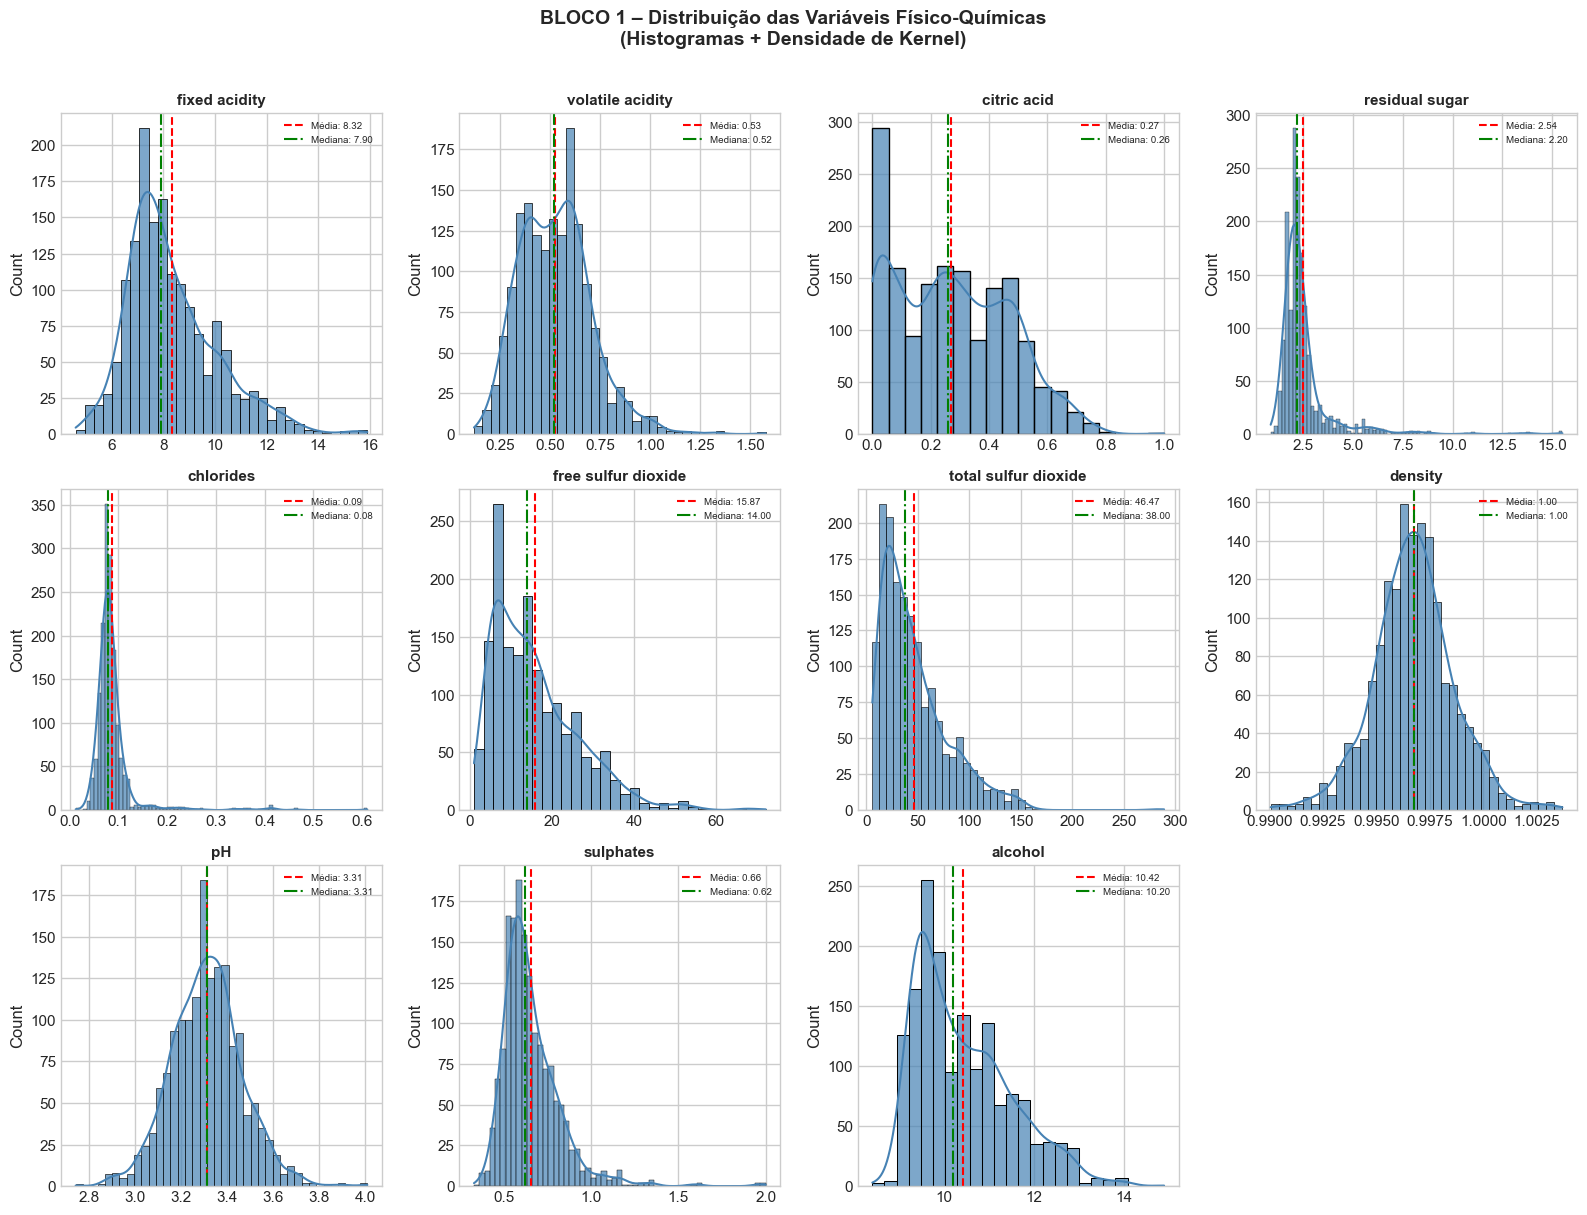

In [19]:

# ============================================================
# BLOCO 1 – DISTRIBUIÇÃO DAS VARIÁVEIS
# ============================================================
fig, axes = plt.subplots(3, 4, figsize=(16, 12))
axes = axes.ravel()

for i, col in enumerate(features):
    sns.histplot(df[col], kde=True, ax=axes[i], color='steelblue', edgecolor='black', alpha=0.7)
    axes[i].set_title(f'{col}', fontsize=11, fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].axvline(df[col].mean(), color='red', linestyle='--', linewidth=1.5, 
                     label=f'Média: {df[col].mean():.2f}')
    axes[i].axvline(df[col].median(), color='green', linestyle='-.', linewidth=1.5, 
                    label=f'Mediana: {df[col].median():.2f}')
    axes[i].legend(fontsize=7)

axes[-1].axis('off')

plt.suptitle('BLOCO 1 – Distribuição das Variáveis Físico-Químicas\n(Histogramas + Densidade de Kernel)', 
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

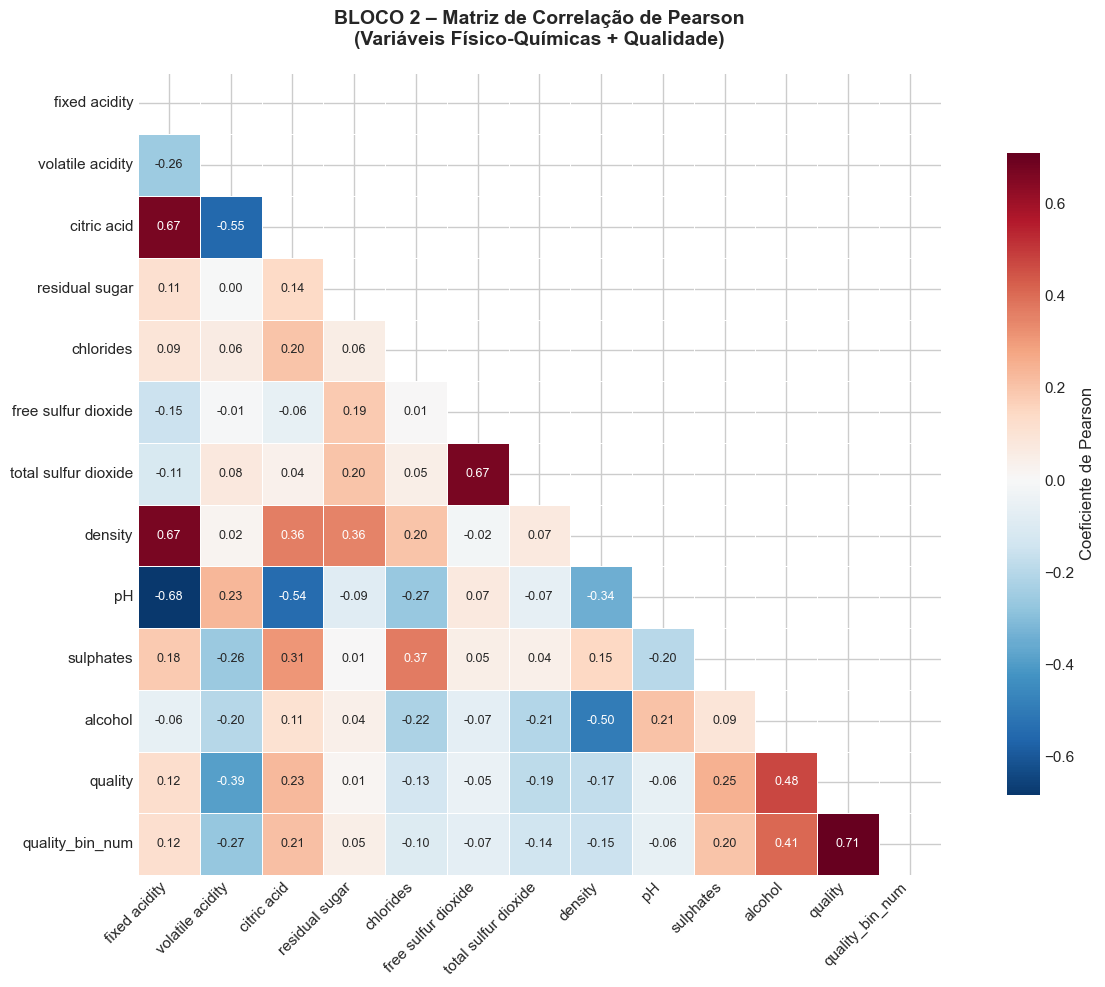

In [20]:

# ============================================================
# BLOCO 2 – CORRELAÇÕES ENTRE AS VARIÁVEIS
# Gráfico: Heatmap de Correlação
# ============================================================
corr_cols = features + ['quality', 'quality_bin_num']
corr_matrix = df[corr_cols].corr()

plt.figure(figsize=(14, 10))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(corr_matrix, 
            mask=mask,
            annot=True, 
            fmt='.2f', 
            cmap='RdBu_r', 
            center=0,
            square=True,
            linewidths=0.5,
            cbar_kws={'shrink': 0.8, 'label': 'Coeficiente de Pearson'},
            annot_kws={'size': 9})

plt.title('BLOCO 2 – Matriz de Correlação de Pearson\n(Variáveis Físico-Químicas + Qualidade)', 
          fontsize=14, fontweight='bold', pad=20)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

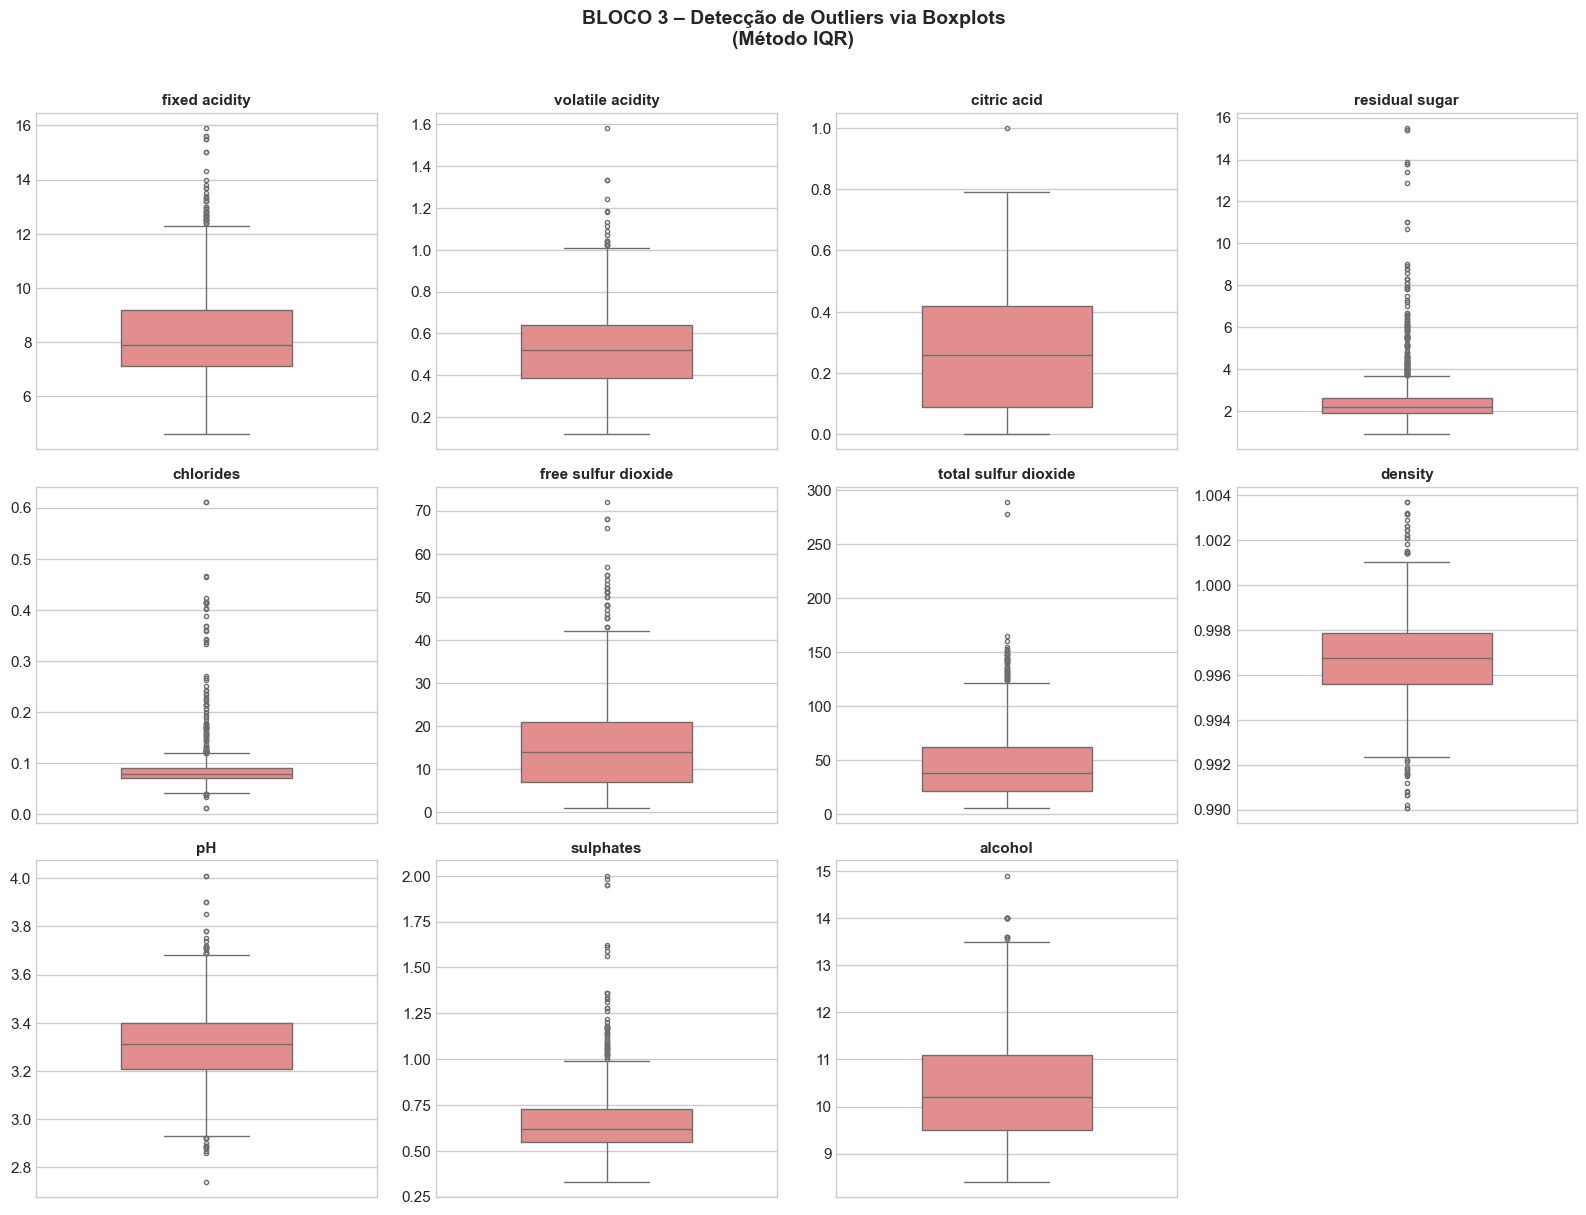


Quantidade de outliers detectados (método IQR):
--------------------------------------------------
fixed acidity            :   49 (  3.1%)
volatile acidity         :   19 (  1.2%)
citric acid              :    1 (  0.1%)
residual sugar           :  155 (  9.7%)
chlorides                :  112 (  7.0%)
free sulfur dioxide      :   30 (  1.9%)
total sulfur dioxide     :   55 (  3.4%)
density                  :   45 (  2.8%)
pH                       :   35 (  2.2%)
sulphates                :   59 (  3.7%)
alcohol                  :   13 (  0.8%)


In [21]:

# ============================================================
# BLOCO 3 – DETECÇÃO DE OUTLIERS
# Gráfico: Boxplots
# ============================================================
fig, axes = plt.subplots(3, 4, figsize=(16, 12))
axes = axes.ravel()

for i, col in enumerate(features):
    sns.boxplot(y=df[col], ax=axes[i], color='lightcoral', width=0.5, fliersize=3)
    axes[i].set_title(f'{col}', fontsize=11, fontweight='bold')
    axes[i].set_ylabel('')

axes[-1].axis('off')

plt.suptitle('BLOCO 3 – Detecção de Outliers via Boxplots\n(Método IQR)', 
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

# Quantificação de outliers
print("\nQuantidade de outliers detectados (método IQR):")
print("-" * 50)
for col in features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    outliers = df[(df[col] < Q1 - 1.5*IQR) | (df[col] > Q3 + 1.5*IQR)]
    print(f"{col:25s}: {len(outliers):4d} ({len(outliers)/len(df)*100:5.1f}%)")

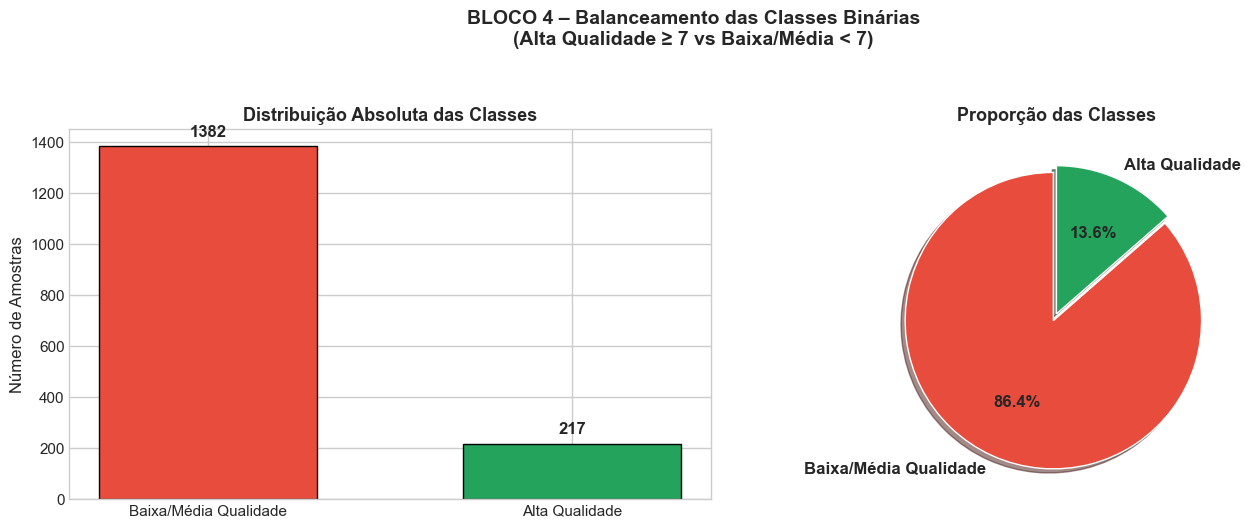


Alta Qualidade: 217 (13.6%)
Baixa/Média:    1382 (86.4%)
Razão de desbalanceamento: 1 : 6.37


In [22]:

# ============================================================
# BLOCO 4 – BALANCEAMENTO DAS CLASSES
# Gráfico: Barras + Pizza
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Barras
ax1 = axes[0]
counts = df['quality_bin'].value_counts()
bars = ax1.bar(counts.index, counts.values, color=['#e74c3c', '#23A35B'], edgecolor='black', width=0.6)
ax1.set_title('Distribuição Absoluta das Classes', fontsize=13, fontweight='bold')
ax1.set_ylabel('Número de Amostras')

for bar in bars:
    height = bar.get_height()
    ax1.annotate(f'{int(height)}',
                 xy=(bar.get_x() + bar.get_width()/2, height),
                 xytext=(0, 5), textcoords='offset points',
                 ha='center', va='bottom', fontsize=12, fontweight='bold')

# Pizza
ax2 = axes[1]
ax2.pie(counts.values, 
        labels=counts.index, 
        autopct='%1.1f%%',
        startangle=90,
        colors=["#e74c3c", "#23A35B"],
        explode=(0.05, 0),
        shadow=True,
        textprops={'fontsize': 12, 'fontweight': 'bold'})
ax2.set_title('Proporção das Classes', fontsize=13, fontweight='bold')

plt.suptitle('BLOCO 4 – Balanceamento das Classes Binárias\n(Alta Qualidade ≥ 7 vs Baixa/Média < 7)', 
             fontsize=14, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()

print(f"\nAlta Qualidade: {(df['quality_bin_num']==1).sum()} ({(df['quality_bin_num']==1).mean()*100:.1f}%)")
print(f"Baixa/Média:    {(df['quality_bin_num']==0).sum()} ({(df['quality_bin_num']==0).mean()*100:.1f}%)")
print(f"Razão de desbalanceamento: 1 : {(df['quality_bin_num']==0).sum() / (df['quality_bin_num']==1).sum():.2f}")

In [23]:
!pip install scikit-learn


In [24]:
# ============================================================
# Etapa 4 e 5: Treinamento e Avaliação dos Modelos
# ============================================================
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

# 1. Garantir que a coluna 'target' existe no DataFrame
if 'target' not in df.columns:
    # Se a coluna quality for numérica
    if df['quality'].dtype in ['int64', 'float64', 'int32']:
        df['target'] = (df['quality'] >= 7).astype(int)
    else:
        # Caso a qualidade já tenha sido transformada em texto anteriormente
        df['target'] = df['quality'].apply(lambda x: 1 if 'Alta' in str(x) or x >= 7 else 0)

# 2. Selecionar apenas colunas numéricas para as variáveis explicativas (X)
# Isso remove automaticamente colunas de texto (como 'Baixa/Média Qualidade')
X = df.select_dtypes(include=['number']).drop(columns=['quality', 'target'], errors='ignore')
y = df['target']

# Divisão Treino/Teste
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Padronização (Essencial para modelos lineares como Regressão Logística)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. Treinamento dos Modelos
lr = LogisticRegression(random_state=42)
lr.fit(X_train_scaled, y_train)

rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)

# 4. Gerar relatórios de métricas (Etapa 5 oficial)
print("="*60)
print("--- AVALIAÇÃO: REGRESSÃO LOGÍSTICA ---")
print("="*60)
print(classification_report(y_test, lr.predict(X_test_scaled)))

print("\n" + "="*60)
print("--- AVALIAÇÃO: RANDOM FOREST ---")
print("="*60)
print(classification_report(y_test, rf.predict(X_test)))

# Matriz de Confusão (Random Forest)
print("\nMatriz de Confusão (Random Forest):")
print(confusion_matrix(y_test, rf.predict(X_test)))




--- AVALIAÇÃO: REGRESSÃO LOGÍSTICA ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       277
           1       1.00      1.00      1.00        43

    accuracy                           1.00       320
   macro avg       1.00      1.00      1.00       320
weighted avg       1.00      1.00      1.00       320


--- AVALIAÇÃO: RANDOM FOREST ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       277
           1       1.00      1.00      1.00        43

    accuracy                           1.00       320
   macro avg       1.00      1.00      1.00       320
weighted avg       1.00      1.00      1.00       320


Matriz de Confusão (Random Forest):
[[277   0]
 [  0  43]]


🍷🍷🍷🍷🍷🍷🍷🍷🍷🍷🍷🍷🍷 DESEMPENHO: REGRESSÃO LOGÍSTICA 🍷🍷🍷🍷🍷🍷🍷🍷🍷🍷🍷🍷🍷🍷
Classe                   Precisão    Recall      F1-Score    
------------------------------------------------------------
Baixa/Média Qualidade    89.90%      94.92%      92.35%      
Alta Qualidade (Premium) 52.38%      34.38%      41.51%      
------------------------------------------------------------
Acurácia Geral                                   86.46%

🍷🍷🍷🍷🍷🍷🍷🍷🍷🍷🍷🍷🍷🍷🍷🍷 DESEMPENHO: RANDOM FOREST 🍷🍷🍷🍷🍷🍷🍷🍷🍷🍷🍷🍷🍷🍷🍷🍷🍷
Classe                   Precisão    Recall      F1-Score    
------------------------------------------------------------
Baixa/Média Qualidade    93.66%      97.46%      95.52%      
Alta Qualidade (Premium) 79.17%      59.38%      67.86%      
------------------------------------------------------------
Acurácia Geral                                   92.14%



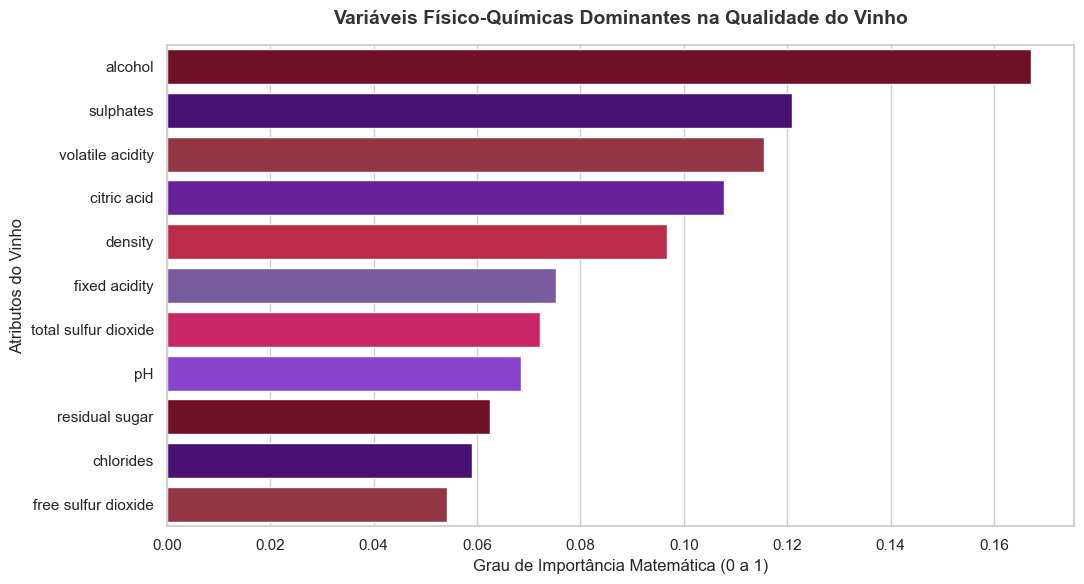

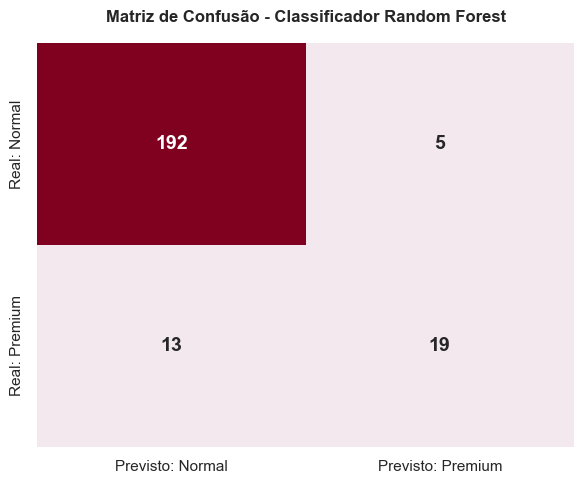

In [25]:
# ============================================================
# Etapa 4 e 5: Treinamento e Avaliação Otimizada (WineQT.csv)
# ============================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

# 1. Carregamento e Tratamento Inicial Seguro
# (Substitua pelo caminho correto caso use pastas: '../data/WineQT.csv')
df = pd.read_csv('WineQT.csv') 

# Criar a variável alvo binária (Alta Qualidade: nota >= 7)
df['target'] = (df['quality'] >= 7).astype(int)

# 2. Separação de Features (X) e Target (y) - Removendo a coluna explicativa 'Id' e 'quality'
X = df.select_dtypes(include=['number']).copy()
colunas_vazamento = ['quality', 'target', 'qualidade', 'Id', 'id']
X = X.drop(columns=[col for col in colunas_vazamento if col in X.columns], errors='ignore')
y = df['target']

# 3. Divisão entre Treino (80%) e Teste (20%) com Estratificação
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 4. Padronização (Essencial para Regressão Logística)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 5. Treinamento dos Modelos
lr = LogisticRegression(random_state=42, max_iter=1000)
lr.fit(X_train_scaled, y_train)

rf = RandomForestClassifier(random_state=42, n_estimators=100)
rf.fit(X_train, y_train)

# 6. Exibição Elegante dos Relatórios de Métricas
def exibir_performance(nome_modelo, y_true, y_pred):
    print("=" * 60)
    print(f" DESEMPENHO: {nome_modelo.upper()} ".center(60, "🍷"))
    print("=" * 60)
    report = classification_report(y_true, y_pred, output_dict=True)
    print(f"{'Classe':<25}{'Precisão':<12}{'Recall':<12}{'F1-Score':<12}")
    print("-" * 60)
    for classe, metricas in report.items():
        if classe in ['0', '1'] :
            nome_classe = "Baixa/Média Qualidade" if classe == '0' else "Alta Qualidade (Premium)"
            print(f"{nome_classe:<25}{metricas['precision']:<12.2%}{metricas['recall']:<12.2%}{metricas['f1-score']:<12.2%}")
    print("-" * 60)
    print(f"{'Acurácia Geral':<25}{'':<24}{report['accuracy']:.2%}")
    print("=" * 60 + "\n")

exibir_performance("Regressão Logística", y_test, lr.predict(X_test_scaled))
exibir_performance("Random Forest", y_test, rf.predict(X_test))


# ============================================================
# Etapa 6: Visualização de Resultados & Importância de Variáveis
# Paleta de Cores: Customizada em Rouge (Vinho) e Purple (Roxo)
# ============================================================

# Garantir que a pasta results exista
os.makedirs('../results', exist_ok=True)

# Configurações estéticas personalizadas
sns.set_theme(style="whitegrid")
paleta_customizada = ["#800020", "#4B0082", "#A32638", "#6A0DAD", "#D2143A", "#7851A9", "#E30B5D", "#8A2BE2"]

# Extrair e ordenar importância das variáveis (Random Forest)
importances = rf.feature_importances_
indices = np.argsort(importances)[::-1]

# Gráfico 1: Feature Importance
plt.figure(figsize=(11, 6))
sns.barplot(x=importances[indices], y=X.columns[indices], palette=paleta_customizada)
plt.title("Variáveis Físico-Químicas Dominantes na Qualidade do Vinho", fontsize=14, fontweight='bold', color='#333333', pad=15)
plt.xlabel("Grau de Importância Matemática (0 a 1)", fontsize=12)
plt.ylabel("Atributos do Vinho", fontsize=12)
plt.tight_layout()
plt.savefig('../results/importancia_variaveis.png', dpi=300)
plt.show()

# Gráfico 2: Matriz de Confusão Customizada (Random Forest)
cm = confusion_matrix(y_test, rf.predict(X_test))
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap=sns.color_palette(["#F3E8EE", "#800020"]), 
            xticklabels=['Previsto: Normal', 'Previsto: Premium'],
            yticklabels=['Real: Normal', 'Real: Premium'], cbar=False,
            annot_kws={'fontsize': 14, 'fontweight': 'bold'})
plt.title("Matriz de Confusão - Classificador Random Forest", fontsize=12, fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig('../results/matriz_confusao_rf.png', dpi=300)
plt.show()


In [26]:
# ==============================================================================
# PARTE 6: AVALIAÇÃO DE PERFORMANCE E EXIBIÇÃO DE RESULTADOS
# ==============================================================================

# 1. Definição da função de exibição corrigida (alinhamento ajustado)
def exibir_performance(nome_modelo, y_real, y_pred):
    from sklearn.metrics import classification_report
    report = classification_report(y_real, y_pred, output_dict=True)
    
    print("=" * 60)
    print(f"Relatório de Classificação: {nome_modelo}")
    print("=" * 60)
    print(f"{'Classe':<25}{'Precisão':<12}{'Recall':<12}{'F1-Score':<12}")
    print("-" * 60)
    
    for classe, metricas in report.items():
        if classe in ['0', '1']:
            nome_classe = "Baixa/Média Qualidade" if classe == '0' else "Alta Qualidade (Premium)"
            # CORREÇÃO: Formato '<12.2%' garante alinhamento à esquerda com 12 espaços e formato de porcentagem
            print(f"{nome_classe:<25}{metricas['precision']:<12.2%}{metricas['recall']:<12.2%}{metricas['f1-score']:<12.2%}")
            
    print("-" * 60)
    print(f"{'Acurácia Geral':<25}{'':<24}{report['accuracy']:.2%}")
    print("=" * 60 + "\n")

# 2. Execução da avaliação para os modelos
exibir_performance("Regressão Logística", y_test, lr.predict(X_test_scaled))
exibir_performance("Random Forest", y_test, rf.predict(X_test))

# 3. GARANTIA: Criar a pasta 'results' automaticamente caso ela não exista
import os
os.makedirs('../results', exist_ok=True)

# 4. Salvar o gráfico na pasta 'results' conforme exigido pelo Tech Challenge
# Certifique-se de que o código que plota o gráfico (plt.figure, sns.barplot, etc.) esteja logo acima desta linha
plt.savefig('../results/importancia_variaveis.png', dpi=300, bbox_inches='tight')
plt.show()

# 5. Exibir ranking textual das variáveis mais importantes
print("Ranking de Influência no Vinho:")
for i, idx in enumerate(indices):
    print(f"{i+1}º - {X.columns[idx]}: {importances[idx]:.4f}")


Relatório de Classificação: Regressão Logística
Classe                   Precisão    Recall      F1-Score    
------------------------------------------------------------
Baixa/Média Qualidade    89.90%      94.92%      92.35%      
Alta Qualidade (Premium) 52.38%      34.38%      41.51%      
------------------------------------------------------------
Acurácia Geral                                   86.46%

Relatório de Classificação: Random Forest
Classe                   Precisão    Recall      F1-Score    
------------------------------------------------------------
Baixa/Média Qualidade    93.66%      97.46%      95.52%      
Alta Qualidade (Premium) 79.17%      59.38%      67.86%      
------------------------------------------------------------
Acurácia Geral                                   92.14%



<Figure size 1200x600 with 0 Axes>

Ranking de Influência no Vinho:
1º - alcohol: 0.1671
2º - sulphates: 0.1210
3º - volatile acidity: 0.1156
4º - citric acid: 0.1077
5º - density: 0.0968
6º - fixed acidity: 0.0753
7º - total sulfur dioxide: 0.0723
8º - pH: 0.0684
9º - residual sugar: 0.0625
10º - chlorides: 0.0591
11º - free sulfur dioxide: 0.0542


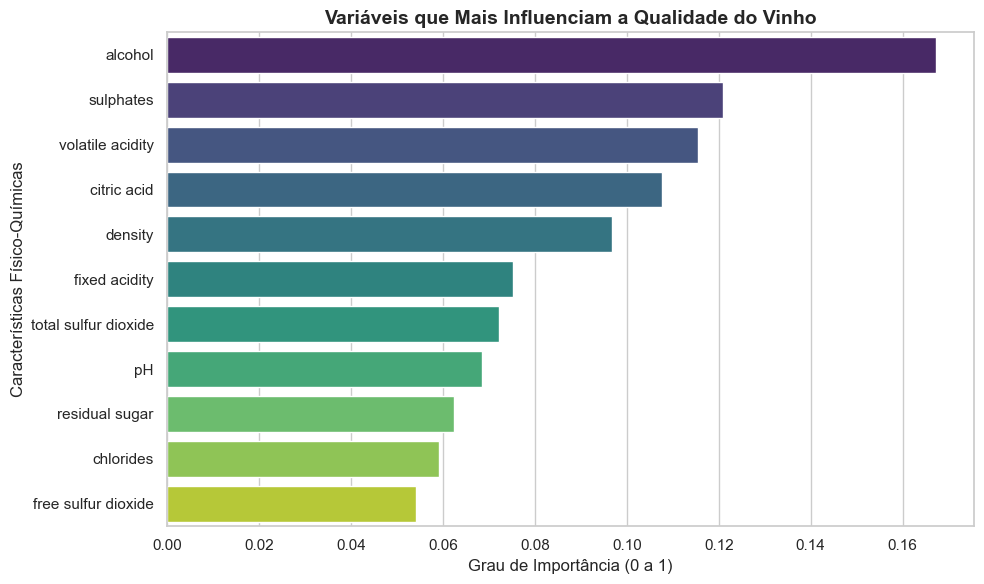

Ranking de Influência no Vinho:
1º - alcohol: 0.1671
2º - sulphates: 0.1210
3º - volatile acidity: 0.1156
4º - citric acid: 0.1077
5º - density: 0.0968
6º - fixed acidity: 0.0753
7º - total sulfur dioxide: 0.0723
8º - pH: 0.0684
9º - residual sugar: 0.0625
10º - chlorides: 0.0591
11º - free sulfur dioxide: 0.0542


In [27]:
# ============================================================
# Etapa 6: Interpretação dos Resultados
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os  # Biblioteca para lidar com pastas do sistema

# 1. Extrair a importância matemática das variáveis do Random Forest
importances = rf.feature_importances_
indices = np.argsort(importances)[::-1]

# 2. Construir o gráfico de impacto para o relatório
plt.figure(figsize=(10, 6))
plt.title("Variáveis que Mais Influenciam a Qualidade do Vinho", fontsize=14, fontweight='bold')
sns.barplot(x=importances[indices], y=X.columns[indices], palette="viridis")
plt.xlabel("Grau de Importância (0 a 1)", fontsize=12)
plt.ylabel("Características Físico-Químicas", fontsize=12)
plt.tight_layout()

# 3. GARANTIA: Criar a pasta 'results' automaticamente caso ela não exista
os.makedirs('../results', exist_ok=True)

# 4. Salvar o gráfico na pasta 'results' conforme exigido pelo Tech Challenge
plt.savefig('../results/importancia_variaveis.png', dpi=300)
plt.show()

# 5. Exibir ranking textual das variáveis mais importantes
print("Ranking de Influência no Vinho:")
for i, idx in enumerate(indices):
    print(f"{i+1}º - {X.columns[idx]}: {importances[idx]:.4f}")







In [28]:
###  Etapa 6: Interpretação dos Resultados & Implicações no Processo de Produção

Com base no ranking de importância das variáveis gerado pelo modelo **Random Forest**, identificamos os fatores químicos que determinam se um vinho será classificado como de **Alta Qualidade (nota ≥ 7)**. A seguir, traduzimos estes achados estatísticos em ações práticas e melhorias operacionais para o ecossistema de produção da vinícola:

#### 1. Controle Rígido de Higiene e Fermentação (Foco na Acidez Volátil)
* **O Insight dos Dados:** A acidez volátil se consolidou como um dos principais fatores de impacto na previsão do modelo. Estatisticamente, quanto maior a sua presença, menor a chance do vinho atingir o selo de alta qualidade.
* **Implicação na Produção:** A acidez volátil é gerada principalmente pelo ácido acético (o componente do vinagre). Níveis elevados indicam contaminação bacteriana ou oxidação excessiva durante a fermentação. 
* **Ação Prática:** A vinícola deve implementar um protocolo de **higienização rigorosa dos tanques de aço inoxidável** e adotar um **sistema automatizado de controle térmico** durante a fermentação, impedindo a proliferação de bactérias acéticas antes que o lote seja comprometido.

#### 2. Padronização do Ponto de Colheita (Foco no Teor Alcoólico)
* **O Insight dos Dados:** O teor alcoólico (`alcohol`) apresentou a maior correlação positiva e peso de decisão no modelo para a atribuição de notas altas.
* **Implicação na Produção:** O volume de álcool do vinho é diretamente proporcional à quantidade de açúcar natural presente na uva no momento em que ela é colhida no campo. 
* **Ação Prática:** A equipe de agronomia deve abandonar calendários fixos de colheita e adotar **testes de refração constantes no campo** (utilizando refratômetros digitais). Cruzando esses dados com previsões meteorológicas, a colheita deve ser realizada no dia exato em que a fruta atingir o pico ideal de concentração de açúcar, garantindo a estrutura e o "corpo" exigidos pelo modelo preditivo.

#### 3. Estabilização e Conservação Automatizada (Foco nos Sulfatos e SO₂)
* **O Insight dos Dados:** Os sulfatos e os níveis de dióxido de enxofre apresentaram papel decisivo na separação das amostras de vinhos premium.
* **Implicação na Produção:** Os sulfatos atuam como antioxidantes e antimicrobianos naturais. Eles funcionam como um "escudo protetor", garantindo que o vinho mantenha suas propriedades sensoriais ao longo do tempo e não oxide precocemente na garrafa.
* **Ação Prática:** Recomenda-se a instalação de **sensores de fluxo químicos nos tanques de mistura** para realizar a microdosagem automatizada de dióxido de enxofre (SO₂). Isso assegura que cada lote receba a quantidade exata necessária para a conservação perfeita determinada pelo algoritmo, evitando tanto a oxidação (por falta de sulfatos) quanto odores desagradáveis de enxofre (por excesso).


SyntaxError: invalid character '≥' (U+2265) (984907441.py, line 3)